#Título del reporte: Laboratorio 10
#Documentación del origen de datos: El comando exacto utilizado para generar el dataset sintético con Synthea (por ejemplo, ./run_synthea -p 500 ...) y la nota aclaratoria indicando que los datos CSV están ignorados en el .gitignore.

##Actividad 2
#Validar la integridad de las 5 tablas:
- Conteo de registros y completitud: Confirmación de volumen de filas y porcentaje de nulos en llaves primarias (Id en patients y encounters).
- Verificación de tipos explícitos: Confirmación con DESCRIBE de que BIRTHDATE es DATE y START/STOP/DATE son TIMESTAMP.
- Integridad referencial: Consultas LEFT JOIN para verificar que todos los registros de encounters, conditions, observations y medications tengan un PATIENT válido en la tabla patients.
- Valores atípicos y rango de fechas: Identificación de posibles incoherencias lógicas (ej. BIRTHDATE > CURRENT_DATE o valores extremos en observations para signos vitales).

Pendiente...

#Actividad 3: Cargar de forma reproducible
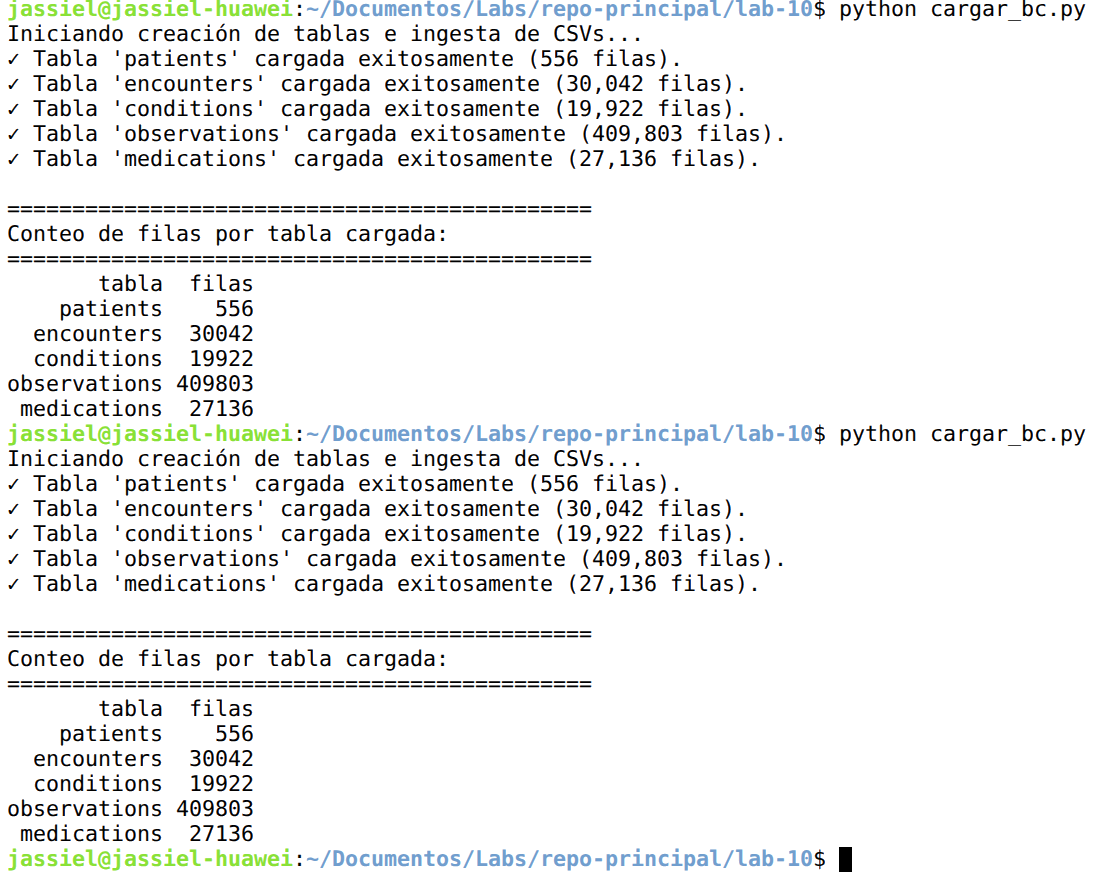

#Actividad 4: Explora el esquema
```mermaid
erDiagram
    patients ||--o{ encounters : "1:N (PATIENT -> Id)"
    patients ||--o{ conditions : "1:N (PATIENT -> Id)"
    patients ||--o{ observations : "1:N (PATIENT -> Id)"
    patients ||--o{ medications : "1:N (PATIENT -> Id)"

    encounters ||--o{ conditions : "1:N (ENCOUNTER -> Id)"
    encounters ||--o{ observations : "1:N (ENCOUNTER -> Id)"
    encounters ||--o{ medications : "1:N (ENCOUNTER -> Id)"

    patients {
        string Id PK
        date BIRTHDATE
        date DEATHDATE
        string FIRST
        string LAST
        string GENDER
        string CITY
    }

    encounters {
        string Id PK
        timestamp START
        timestamp STOP
        string PATIENT FK
        string ENCOUNTERCLASS
        double TOTAL_CLAIM_COST
    }

    conditions {
        date START
        date STOP
        string PATIENT FK
        string ENCOUNTER FK
        string CODE
        string DESCRIPTION
    }

    observations {
        timestamp DATE
        string PATIENT FK
        string ENCOUNTER FK
        string CODE
        string DESCRIPTION
        string VALUE
        string UNITS
    }

    medications {
        timestamp START
        timestamp STOP
        string PATIENT FK
        string ENCOUNTER FK
        string CODE
        string DESCRIPTION
        double TOTALCOST
    }
```

In [2]:
#Actividad 5: Auditar antes de confiar
- Integridad de Lllave primaria:** Confirmada (0 duplicados en la tabla `patients`).
- Validez cronológica: confirmada (0 eventos registrados antes de la fecha de nacimiento).
- Completitud de datos: 100% de los registros en `observations` poseen valor válido (`VALUE`).
- Hallazgo de integridad referencial: se detectaron 10 encuentros huérfanos cuyas llaves foráneas (`PATIENT`) no cruzan con el catálogo de `patients`.